# 7. Laplace transforms, transfer functions and Fourier series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/sympy-for-engineers/blob/main/notebooks/07_laplace_and_fourier.ipynb)

Process control, circuits and vibrations all use the Laplace transform to turn differential
equations into algebra. The table lookups and partial fractions are exactly what SymPy automates.

**Worked examples:** step responses of first- and second-order systems, overshoot, a dead-time
process, closed-loop stability with a proportional controller, and the Fourier series of a
square wave.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

sp.init_printing(use_latex="mathjax")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

t = sp.symbols("t", positive=True)
s = sp.symbols("s")

## 7.1 The transform table, generated

`noconds=True` returns only the transform, without the region of convergence.

In [2]:
a, w = sp.symbols("a omega", positive=True)

table = [sp.S(1), t, sp.exp(-a * t), t * sp.exp(-a * t), sp.sin(w * t), sp.cos(w * t), sp.exp(-a * t) * sp.sin(w * t)]
sp.Matrix([[f, sp.laplace_transform(f, t, s, noconds=True)] for f in table])

⎡                      1      ⎤
⎢      1               ─      ⎥
⎢                      s      ⎥
⎢                             ⎥
⎢                     1       ⎥
⎢      t              ──      ⎥
⎢                      2      ⎥
⎢                     s       ⎥
⎢                             ⎥
⎢     -a⋅t             1      ⎥
⎢    ℯ               ─────    ⎥
⎢                    a + s    ⎥
⎢                             ⎥
⎢      -a⋅t           1       ⎥
⎢   t⋅ℯ            ────────   ⎥
⎢                         2   ⎥
⎢                  (a + s)    ⎥
⎢                             ⎥
⎢                      ω      ⎥
⎢   sin(ω⋅t)        ───────   ⎥
⎢                    2    2   ⎥
⎢                   ω  + s    ⎥
⎢                             ⎥
⎢                      s      ⎥
⎢   cos(ω⋅t)        ───────   ⎥
⎢                    2    2   ⎥
⎢                   ω  + s    ⎥
⎢                             ⎥
⎢ -a⋅t                 ω      ⎥
⎢ℯ    ⋅sin(ω⋅t)  ─────────────⎥
⎢                 2          2⎥
⎣       

## 7.2 The inverse transform and partial fractions

By hand you would expand in partial fractions and look each term up. `sp.apart` shows the
expansion; `inverse_laplace_transform` does both steps.

In [3]:
Y = 1 / (s * (s + 1) * (s + 2))
sp.apart(Y, s), sp.inverse_laplace_transform(Y, s, t)

⎛                                    -2⋅t⎞
⎜    1         1      1   1    -t   ℯ    ⎟
⎜───────── - ───── + ───, ─ - ℯ   + ─────⎟
⎝2⋅(s + 2)   s + 1   2⋅s  2           2  ⎠

## 7.3 Solving a differential equation with Laplace transforms

**Problem.** $\ddot y + 3\dot y + 2y = 1$ with $y(0) = \dot y(0) = 0$.

SymPy transforms derivatives using the rule $\mathcal{L}\{\dot y\} = sY(s) - y(0)$:

In [4]:
y = sp.Function("y")
ode = y(t).diff(t, 2) + 3 * y(t).diff(t) + 2 * y(t) - 1

transformed = sp.laplace_transform(ode, t, s, noconds=True)
transformed

 2                                                                             ↪
s ⋅LaplaceTransform(y(t), t, s) + 3⋅s⋅LaplaceTransform(y(t), t, s) - s⋅y(0) +  ↪
                                                                               ↪

↪                                           ⎛d       ⎞│      1
↪ 2⋅LaplaceTransform(y(t), t, s) - 3⋅y(0) - ⎜──(y(t))⎟│    - ─
↪                                           ⎝dt      ⎠│t=0   s

In [5]:
# name the unknown transform Y(s), insert the initial conditions, and solve the algebraic equation
Ys = sp.symbols("Y")
initial = {sp.LaplaceTransform(y(t), t, s): Ys, y(0): 0, sp.Subs(sp.Derivative(y(t), t), t, 0): 0}

Y_solution = sp.solve(transformed.subs(initial), Ys)[0]
y_t = sp.inverse_laplace_transform(Y_solution, s, t)
Y_solution, y_t

⎛                             -2⋅t⎞
⎜       1          1    -t   ℯ    ⎟
⎜────────────────, ─ - ℯ   + ─────⎟
⎜  ⎛ 2          ⎞  2           2  ⎟
⎝s⋅⎝s  + 3⋅s + 2⎠                 ⎠

In [6]:
# verify against dsolve, and check the final value theorem: y(∞) = lim s→0 of s·Y(s)
direct = sp.dsolve(ode, y(t), ics={y(0): 0, y(t).diff(t).subs(t, 0): 0}).rhs
assert sp.simplify(y_t - direct) == 0
assert sp.limit(s * Y_solution, s, 0) == sp.limit(y_t, t, sp.oo) == sp.Rational(1, 2)

## 7.4 First-order process

**Problem.** A thermocouple, a stirred tank and an RC circuit share the transfer function
$G(s) = \dfrac{K}{\tau s + 1}$. Find the response to a unit step and to a unit ramp.

In [7]:
K, tau = sp.symbols("K tau", positive=True)
G1 = K / (tau * s + 1)

step = sp.inverse_laplace_transform(G1 / s, s, t)        # step input: 1/s
ramp = sp.inverse_laplace_transform(G1 / s**2, s, t)     # ramp input: 1/s^2
step, ramp

⎛  ⎛     -t ⎞    ⎛           -t ⎞⎞
⎜  ⎜     ───⎟    ⎜           ───⎟⎟
⎜  ⎜      τ ⎟    ⎜            τ ⎟⎟
⎝K⋅⎝1 - ℯ   ⎠, K⋅⎝t - τ + τ⋅ℯ   ⎠⎠

In [8]:
# verify: 63.2 % of the final change is reached after one time constant
fraction = (step / K).subs(t, tau)
assert fraction == 1 - sp.exp(-1)
float(fraction)

0.6321205588285577

The ramp response settles to $K(t - \tau)$: the output lags the input by one time constant.
This is the dynamic error of a thermometer in a bath whose temperature is rising.

## 7.5 Second-order process and overshoot

**Problem.** $G(s) = \dfrac{1}{s^2 + 2\zeta s + 1}$ (time in units of $1/\omega_n$).
How does the step response depend on the damping ratio $\zeta$?

In [9]:
zeta = sp.symbols("zeta", positive=True)
G2 = 1 / (s**2 + 2 * zeta * s + 1)

step_responses = {
    z: sp.simplify(sp.inverse_laplace_transform(G2.subs(zeta, z) / s, s, t))
    for z in (sp.Rational(1, 5), sp.Rational(1, 2), sp.Rational(7, 10), sp.S(1), sp.S(2))
}
step_responses[sp.Rational(1, 2)]

          -t               
          ───              
           2     ⎛√3⋅t   π⎞
    2⋅√3⋅ℯ   ⋅sin⎜──── + ─⎟
                 ⎝ 2     3⎠
1 - ───────────────────────
               3           

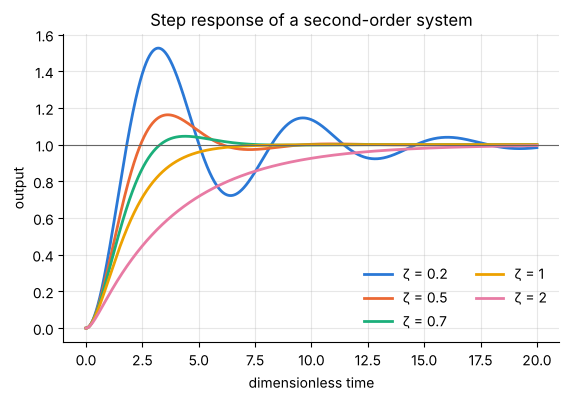

In [10]:
ts = np.linspace(1e-6, 20, 2001)
curves = {z: sp.lambdify(t, expr, "numpy")(ts) for z, expr in step_responses.items()}

fig, ax = plt.subplots()
for z, values in curves.items():
    ax.plot(ts, values, label=f"ζ = {float(z):g}")
ax.axhline(1, color="0.4", lw=0.8)
ax.set(xlabel="dimensionless time", ylabel="output", title="Step response of a second-order system")
ax.legend(frameon=False, ncols=2, loc="lower right");

**Verify.** Textbooks give the overshoot of an underdamped system as
$\exp\!\left(-\dfrac{\pi\zeta}{\sqrt{1-\zeta^2}}\right)$. Compare with the peaks of the curves.

In [11]:
for z in (sp.Rational(1, 5), sp.Rational(1, 2), sp.Rational(7, 10)):
    formula = float(sp.exp(-sp.pi * z / sp.sqrt(1 - z**2)))
    measured = curves[z].max() - 1
    print(f"ζ = {float(z):.1f}   formula {formula:.4f}   from the curve {measured:.4f}")
    assert abs(formula - measured) < 1e-3

ζ = 0.2   formula 0.5266   from the curve 0.5266
ζ = 0.5   formula 0.1630   from the curve 0.1630
ζ = 0.7   formula 0.0460   from the curve 0.0460


## 7.6 Dead time

Transport through a pipe delays a signal by $\theta$, which multiplies the transfer function by
$e^{-\theta s}$. The inverse transform contains a Heaviside step that switches the response on
at $t = \theta$.

In [12]:
theta = sp.symbols("theta", positive=True)
fopdt = sp.inverse_laplace_transform(K * sp.exp(-theta * s) / (s * (tau * s + 1)), s, t)
fopdt

  ⎛            -(t - θ)          ⎞
  ⎜            ─────────         ⎟
  ⎜                τ             ⎟
K⋅⎝θ(t - θ) - ℯ         ⋅θ(t - θ)⎠

## 7.7 Transfer-function objects and closed-loop stability

`sympy.physics.control` provides `TransferFunction` objects that can be connected in series and
in feedback loops.

**Problem.** The process $G_p(s) = \dfrac{1}{(s+1)(s+2)(s+3)}$ is controlled by a proportional
controller with gain $K_c$ in a unit-feedback loop. For which gains is the loop stable?

In [13]:
from sympy.physics.control.lti import Feedback, Series, TransferFunction

Kc = sp.symbols("K_c", positive=True)
process = TransferFunction(1, (s + 1) * (s + 2) * (s + 3), s)
controller = TransferFunction(Kc, 1, s)

closed_loop = Feedback(Series(controller, process), TransferFunction(1, 1, s)).doit().simplify()
closed_loop

             K_c             
─────────────────────────────
K_c + (s + 1)⋅(s + 2)⋅(s + 3)

In [14]:
process.poles(), process.is_stable(), closed_loop.dc_gain()

([-3, -2, -1], True, K_c/(K_c + 6))

The open-loop process is stable. The closed-loop gain at steady state is $K_c/(K_c + 6)$, so a
proportional controller always leaves an offset, which shrinks as $K_c$ grows. But the gain
cannot be raised indefinitely.

**By hand** you would build a Routh array. An equivalent route: at the stability limit a pair of
poles sits on the imaginary axis, so substitute $s = i\omega$ in the characteristic equation and
require the real and imaginary parts to vanish.

In [15]:
omega = sp.symbols("omega", positive=True)
characteristic = sp.expand(closed_loop.den)

on_axis = sp.expand(characteristic.subs(s, sp.I * omega))
limit = sp.solve([sp.re(on_axis), sp.im(on_axis)], [Kc, omega], dict=True)[0]
limit

{K_c: 60, ω: √11}

In [16]:
# verify: stable just below the ultimate gain, unstable just above it
assert limit[Kc] == 60
assert closed_loop.subs(Kc, 59).is_stable() and not closed_loop.subs(Kc, 61).is_stable()

The ultimate gain is $K_{cu} = 60$ and the loop then oscillates with frequency
$\omega_u = \sqrt{11}$ rad per unit time. The root locus shows the poles crossing into the
right half-plane.

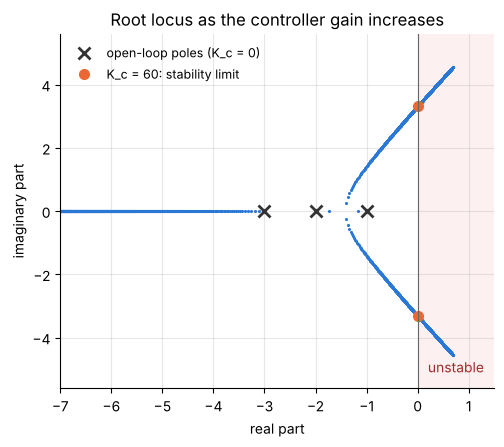

In [17]:
gains = np.linspace(0, 150, 600)
poles = np.array([np.roots(sp.Poly(characteristic.subs(Kc, g), s).all_coeffs()).astype(complex) for g in gains])
poles.sort(axis=1)

fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.axvspan(0, 1.5, color="#e34948", alpha=0.08, lw=0)
ax.plot(poles.real, poles.imag, ".", ms=2.5, color="#2a78d6")
ax.plot(poles[0].real, poles[0].imag, "x", color="0.2", ms=8, mew=2, label="open-loop poles (K_c = 0)")
ax.plot([0, 0], [np.sqrt(11), -np.sqrt(11)], "o", color="#eb6834", ms=7, label="K_c = 60: stability limit")
ax.axvline(0, color="0.4", lw=0.8)
ax.text(0.2, -5.1, "unstable", color="#a32c2b")
ax.set(xlabel="real part", ylabel="imaginary part", xlim=(-7, 1.5), ylim=(-5.6, 5.6), title="Root locus as the controller gain increases")
ax.legend(frameon=False, loc="upper left", fontsize=9);

## 7.8 Fourier series

Any periodic signal is a sum of sines and cosines. `fourier_series` computes the coefficients.

**Example: a square wave** of amplitude 1 and period $2\pi$.

In [18]:
x = sp.symbols("x")
square = sp.Piecewise((-1, x < 0), (1, True))

series = sp.fourier_series(square, (x, -sp.pi, sp.pi))
series.truncate(4)

4⋅sin(x)   4⋅sin(3⋅x)   4⋅sin(5⋅x)   4⋅sin(7⋅x)
──────── + ────────── + ────────── + ──────────
   π          3⋅π          5⋅π          7⋅π    

Only odd harmonics appear, with amplitudes $4/(n\pi)$.

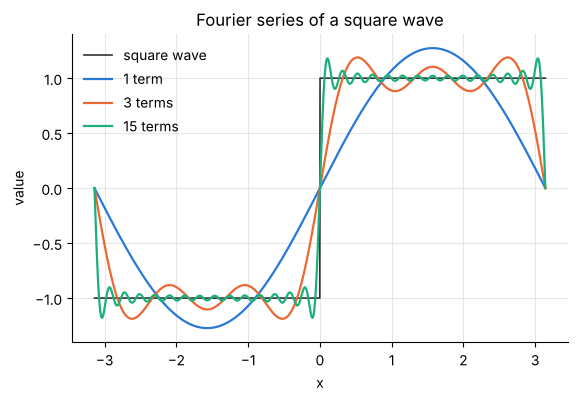

In [19]:
xs = np.linspace(-np.pi, np.pi, 2000)
fig, ax = plt.subplots()
ax.plot(xs, np.sign(xs), color="0.2", lw=1.2, label="square wave")
for terms in (1, 3, 15):
    ax.plot(xs, sp.lambdify(x, series.truncate(terms), "numpy")(xs), lw=1.6, label=f"{terms} term{'s' if terms > 1 else ''}")
ax.set(xlabel="x", ylabel="value", title="Fourier series of a square wave")
ax.legend(frameon=False, loc="upper left");

In [20]:
# the overshoot next to the jump does not shrink as terms are added: the Gibbs phenomenon
overshoot = sp.lambdify(x, series.truncate(60), "numpy")(np.linspace(0.001, 0.5, 5000)).max() - 1
print(f"overshoot with 60 terms: {overshoot:.1%} of the amplitude (about 9 % of the jump)")
assert 0.17 < overshoot < 0.19

overshoot with 60 terms: 17.9% of the amplitude (about 9 % of the jump)


This is why sharp edges in signals ring when they pass through a filter that removes high
frequencies.

## Exercises

1. Find the impulse response of the first-order process (input transform equal to 1) and check
   that it is the time derivative of the step response.
2. A second-order system has 10 % overshoot. Solve the overshoot formula for $\zeta$ with `nsolve`.
3. Add integral action: replace the controller by $K_c\left(1 + \dfrac{1}{\tau_I s}\right)$ with
   $\tau_I = 2$. Show that the steady-state offset disappears and find the new ultimate gain.
4. Compute the Fourier series of a triangular wave, `sp.Abs(x)` on $(-\pi, \pi)$. Why do its
   coefficients fall off faster than those of the square wave?
5. Use the final value theorem to find the steady-state error of the PI-controlled loop of
   exercise 3 to a unit ramp in the set point. (It is finite, $12/K_c$, for $K_c$ below the
   ultimate gain of exercise 3. With the proportional controller of 7.7 the error grows without
   bound.)